### Pseudo-OHLC Data Generation

We can generate fake OHLC chart and use this fake chart to train our model

### Here a real chart of BTCUSDT at 16 July 2026 from 4 PM to PM

In [1]:
import pandas as pd
import requests

url = "https://api.bybit.com/v5/market/kline"
params = {
    "category": "linear", 
    "symbol": "BTCUSDT",
    "interval": "1",    
    "start": 1784206800*1000,
    "end": 1784210400*1000,
    "limit": 1000
}

req = requests.get(url, params)

data = req.json().get('result').get('list')

columns = ["timestamp", "open", "high", "low", "close", "volume", "quote_volume"]
df = pd.DataFrame(data, columns=columns)

# changes values to float
num_cols = ["open", "high", "low", "close", "volume", "quote_volume"]
df[num_cols] = df[num_cols].astype(float)

# timestamp -> datetime
df["timestamp"] = pd.to_datetime(df["timestamp"].astype("int64"), unit="ms")
#df['timestamp'] = pd.to_timedelta(range(len(df)), unit="m") 


# normallize prices
base_price = df.loc[0]['open']
df[['open', 'high', 'close', 'low']] = (df[['open', 'high', 'close', 'low']] - base_price) / base_price * 100

print(df)

             timestamp      open      high       low     close   volume  \
0  2026-07-16 14:00:00  0.000000  0.077856 -0.035120  0.077856  117.687   
1  2026-07-16 13:59:00  0.006216  0.006216 -0.028749  0.000000   40.925   
2  2026-07-16 13:58:00 -0.120280  0.006216 -0.120435  0.006216   26.500   
3  2026-07-16 13:57:00 -0.103186 -0.036985 -0.164569 -0.120280  102.525   
4  2026-07-16 13:56:00 -0.139860 -0.097747 -0.155090 -0.103186   21.530   
..                 ...       ...       ...       ...       ...      ...   
56 2026-07-16 13:04:00 -0.578711 -0.575914 -0.628750 -0.609791   17.521   
57 2026-07-16 13:03:00 -0.629993 -0.541881 -0.629993 -0.578711   68.802   
58 2026-07-16 13:02:00 -0.570475 -0.550117 -0.632013 -0.629993   24.040   
59 2026-07-16 13:01:00 -0.593319 -0.556644 -0.607926 -0.570475   19.938   
60 2026-07-16 13:00:00 -0.642581 -0.585082 -0.659985 -0.593319   31.631   

    quote_volume  
0   7.576137e+06  
1   2.633493e+06  
2   1.704509e+06  
3   6.591392e+06  
4   

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight semibold, now using 700.


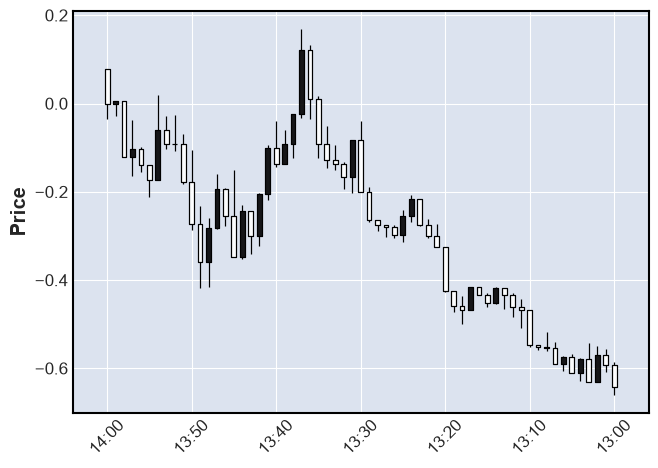

In [ ]:
import mplfinance as mpf

#index
df = df.set_index("timestamp")
# plotting
mpf.plot(df, type='candle')


### Here we generate fake chart

In [ ]:
import pandas as pd
import random

data = [0]*60
base_price = 1
for i in range(60):
    timestamp = (1784206800 + 60*i)*1000
    if i==0: 
        price_o = base_price
        price_c = price_o + random.uniform(-0.10, 0.10)
        price_h = max(price_o, price_c) + random.uniform(0.00, 0.03)
        price_l = min(price_o, price_c) - random.uniform(0.00, 0.03)
    else:
        price_o = data[i-1][4]
        price_c = price_o + random.uniform(-0.10, 0.10)
        price_h = max(price_o, price_c) + random.uniform(0.00, 0.03)
        price_l = min(price_o, price_c) - random.uniform(0.00, 0.03)
        
        
    #              0         1        2        3        4     5  6
    data[i] = [timestamp, price_o, price_h, price_l, price_c, 1, 1]

columns = ["timestamp", "open", "high", "low", "close", "volume", "quote_volume"]
df = pd.DataFrame(data, columns=columns)

print(df)

        timestamp      open      high       low     close  volume  \
0   1784206800000  1.000000  1.025494  0.873138  0.902465       1   
1   1784206860000  0.902465  0.984200  0.884379  0.971756       1   
2   1784206920000  0.971756  0.993344  0.908661  0.934534       1   
3   1784206980000  0.934534  0.949852  0.846411  0.865282       1   
4   1784207040000  0.865282  0.882033  0.794510  0.822692       1   
5   1784207100000  0.822692  0.835167  0.790695  0.805927       1   
6   1784207160000  0.805927  0.827672  0.765642  0.789483       1   
7   1784207220000  0.789483  0.806202  0.681786  0.710487       1   
8   1784207280000  0.710487  0.796748  0.698558  0.781053       1   
9   1784207340000  0.781053  0.794236  0.730204  0.743997       1   
10  1784207400000  0.743997  0.761761  0.632960  0.658339       1   
11  1784207460000  0.658339  0.673365  0.643330  0.660246       1   
12  1784207520000  0.660246  0.758966  0.632524  0.745862       1   
13  1784207580000  0.745862  0.769

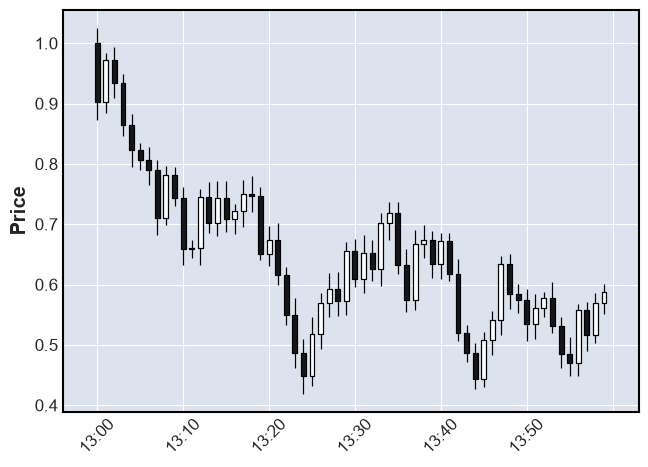

In [23]:
import mplfinance as mpf

df["timestamp"] = pd.to_datetime(df["timestamp"].astype("int64"), unit="ms")
#index
df = df.set_index("timestamp")
# plotting
mpf.plot(df, type='candle')